In [12]:
import pandas as pd
from neuprint import Client
from neuprint import fetch_adjacencies, NeuronCriteria as NC, fetch_synapses, SynapseCriteria as SC, fetch_neurons
import plotly.express as px
import numpy as np
import plotly.io as pio
pio.renderers.default = 'browser'
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pre_HP
import elbow_functions
import Handshake_function_v1
import Handshake_pair_v2
import HP_plot_v2
import NT_functions
import reliability_filter
import Hub_analysis
import yaml
import os
import openpyxl
from pathlib import Path
from kneed import KneeLocator
import cProfile
import pstats
import pickle
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.cluster.hierarchy import linkage, leaves_list, dendrogram
from scipy.spatial.distance import pdist
from matplotlib.colors import LinearSegmentedColormap
import cnsplots


# Paths
cfg = pre_HP.configpath()
data_dir = Path(cfg['data_dir'])
old_data_dir = Path(cfg['old_data_dir'])
elbow_related = Path(cfg['elbow_related'])
concat_related = Path(cfg['concat_related'])
bipartite_folder = Path(cfg['bipartite_folder'])
client = Client(f"https://{cfg['client']}",
                dataset=cfg['dataset'],
                token=cfg['token']) 

## Cell type list


In [2]:
#  ----------------------------------- Reliability Method  -------------------------------------------- #
#top 5 inputs and outputs (weighted rank)
concat_top_input_output_5_weight_median = pd.read_csv(concat_related/ "concat_top_input_output_5_weight_median.csv")

# Load ALL celltypes and cts >= 10
all_ol_ct = pd.read_excel(data_dir/"supplement_table"/"Sup_Table_1_Cell-types_and_counts_final.xlsx")
all_ol_ct_R = all_ol_ct[all_ol_ct["instance"] != all_ol_ct["cell_type"] + "_L"].reset_index(drop=True) # only right side
all_celltypes_R_list = (all_ol_ct_R[['cell_type', 'Group']].drop_duplicates().set_index('cell_type')['Group'].to_dict()) # all cts 
all_celltypes_list_greater_or_eq_10 = (all_ol_ct_R.loc[all_ol_ct_R['no. of cells'] >= 10, ['cell_type', 'Group']].drop_duplicates().set_index('cell_type')['Group'].to_dict()) # filtered >= 10 this criteria removed all non-optic lobe neurons (VPN, ONCN, ONIN, VCN)

# All NTs
NT_all_cts = pd.read_csv(data_dir/ "NT_all_cts.csv")
nt_dict = NT_all_cts.set_index('cell_type')['dominant_nt'].to_dict()

# hub neurons 
hub_neurons = pd.read_csv(data_dir / 'hubs'/ "hub_neurons.csv")
# ############################# Reliability HP (v3) ##########################################
# #  Saved dictionary of first part of bipartite pair (major parents)
with open(data_dir / "input_monopartite_table_v3.pkl", "rb") as f:
    input_monopartite_table_v3 = pickle.load(f)

with open(data_dir / "output_monopartite_table_v3.pkl", "rb") as f:
    output_monopartite_table_v3 = pickle.load(f)


#  ALl parents
with open(data_dir/ "all_OL_input_monopartite_table_v3.pkl", "rb") as f:
    all_OL_input_monopartite_table_v3 = pickle.load(f)

with open(data_dir /"all_OL_output_monopartite_table_v3.pkl", "rb") as f:
    all_OL_output_monopartite_table_v3 = pickle.load(f)


#Saved dictionaries of second part of bipartite pair (All partners considered)
with open(data_dir / "bipartite_output_parent_input_partner_v3.pkl", "rb") as f:
    bipartite_parent_output_v3 = pickle.load(f)

with open(data_dir / "bipartite_input_parent_output_partner_v3.pkl", "rb") as f:
    bipartite_parent_input_v3 = pickle.load(f)

# 0.8 partner reliability cutoff
cut_bipartite_parent_output_v3 = bipartite_parent_output_v3[bipartite_parent_output_v3["parent_reliability_2"] >= 0.8]
cut_bipartite_parent_input_v3 = bipartite_parent_input_v3[bipartite_parent_input_v3["parent_reliability_2"] >= 0.8]

# # #############################90% cumsum dist of partner from all parents (all_celltypes_list_greater_or_eq_10) ##########################################
with open(data_dir / "df_all_parents_partners_95_input.pkl", "rb") as f:
    df_all_parents_partners_95_input = pickle.load(f)

with open(data_dir / "df_all_parents_partners_95_output.pkl", "rb") as f:
    df_all_parents_partners_95_output = pickle.load(f)

In [3]:
# random_celltypes_list = {
#     'Mi9':'ONIN', 'Pm2a':'ONIN', 'Dm2':'ONIN', 'Mi15':'ONIN', 'Mi10':'ONIN', 'Pm3':'ONIN', 'Pm10':'ONIN', 'Dm12':'ONIN',
#     'Mi13':'ONIN', 'Dm3a':'ONIN', 'Dm3b':'ONIN', 'Pm9':'ONIN', 'Dm3c':'ONIN', 'Dm20':'ONIN', 'Cm3':'ONIN', 'Dm15':'ONIN', 'LPi34':'ONIN',
#     'Mi18':'ONIN', 'LPi3412':'ONIN', 'LPi21':'ONIN', 'LPi12':'ONIN', 'Cm5':'ONIN', 'Dm18':'ONIN', 'Pm12':'ONIN', 'Li22':'ONIN',
#     'Cm8':'ONIN', 'Cm6':'ONIN', 'Mi1':'ONIN', 'Mi4':'ONIN', 'Pm4':'ONIN', 'Pm2b':'ONIN', 'Mi2':'ONIN', 'Dm9':'ONIN', 'Pm1':'ONIN', 'Li14':'ONIN',
#     'Li25':'ONIN', 'Dm10':'ONIN', 'Dm8a':'ONIN', 'Pm5':'ONIN', 'Tm24':'ONIN', 'Li21':'ONIN', 'Dm8b':'ONIN', 'Dm6':'ONIN', 'Mi14':'ONIN',
#     'Dm1':'ONIN', 'Cm7':'ONIN', 'Dm13':'ONIN', 'LPi2c':'ONIN', 'Dm4':'ONIN', 'LPi43':'ONIN', 'Li23':'ONIN', 'Cm1':'ONIN',
#     'Dm19':'ONIN', 'Pm8':'ONIN',

#     'Tm3':'ONCN', 'Tm2':'ONCN', 'L2':'ONCN', 'L5':'ONCN', 'TmY5a':'ONCN', 'Tm4':'ONCN', 'Tm1':'ONCN', 'T2':'ONCN',
#     'Y3':'ONCN', 'T2a':'ONCN', 'Tm6':'ONCN', 'Tm20':'ONCN', 'T3':'ONCN', 'Tm5Y':'ONCN', 'T5a':'ONCN', 'L3':'ONCN', 'L1':'ONCN', 'T5c':'ONCN',
#     'T4c':'ONCN', 'T4a':'ONCN', 'T5b':'ONCN', 'TmY3':'ONCN', 'C3':'ONCN', 'T4b':'ONCN', 'TmY18':'ONCN', 'T4d':'ONCN', 'TmY14':'ONCN',
#     'T5d':'ONCN', 'TmY15':'ONCN', 'Tm9':'ONCN', 'TmY10':'ONCN', 'TmY17':'ONCN', 'Tm12':'ONCN', 'Tm37':'ONCN', 'TmY4':'ONCN',
#     'Tm5c':'ONCN', 'Tm16':'ONCN', 'TmY13':'ONCN', 'MeLo8':'ONCN', 'MeLo9':'ONCN', 'TmY21':'ONCN', 'TmY9a':'ONCN', 'L4':'ONCN',
#     'TmY9b':'ONCN', 'Tm39':'ONCN', 'Tm5a':'ONCN', 'C2':'ONCN', 'TmY19a':'ONCN', 'Y11':'ONCN', 'TmY20':'ONCN', 'Tm29':'ONCN',
#     'Tm5b':'ONCN', 'TmY16':'ONCN', 'Tm38':'ONCN', 'Y13':'ONCN', 'Tlp13':'ONCN', 'MeLo10':'ONCN', 'Tlp12':'ONCN',
#     'Y12':'ONCN', 'LOLP1':'ONCN', 'T1':'ONCN', 'MeLo1':'ONCN', 'Tm32':'ONCN', 'Tlp14':'ONCN', 'Y14':'ONCN', 'Lawf1':'ONCN',
#     'TmY19b':'ONCN', 'Tm31':'ONCN', 'MeLo2':'ONCN', 'MeLo13':'ONCN', 'MeLo12':'ONCN', 'Tm33':'ONCN',
    
#     'LC12':'VPN','LC17':'VPN', 'LC10a':'VPN', 'LC11':'VPN', 'LPLC1':'VPN', 'LPLC2':'VPN', 'LC9':'VPN', 'LLPC1':'VPN', 'LC4':'VPN', 
#     'LPLC4':'VPN', 'LC18':'VPN', 'LC10d':'VPN', 'MeVPMe2':'VPN', 'LC14b':'VPN', 'LC21':'VPN', 'MeVPMe1':'VPN', 'LLPC3':'VPN', 'LLPC2':'VPN', 
#     'LC14a-1':'VPN', 'LPC1':'VPN', 'LC15':'VPN','LC13':'VPN', 'LC16':'VPN', 'MeVPOL1':'VPN', 'LC6':'VPN', 'LT52':'VPN', 'LC20b':'VPN', 
#     'aMe5':'VPN', 'LC10b': 'VPN', 'LC10c-1': 'VPN', 'LC10c-2': 'VPN', 'LC10e': 'VPN', 'LC14a-2':'VPN', 'LC22':'VPN', 'LC20a':'VPN', 
#     'LC24':'VPN', 'LPC2':'VPN', 'MeTu2a': 'VPN', 'MeTu3b': 'VPN', 'MeTu3c': 'VPN', 'MeTu4a': 'VPN', 'MeVP1': 'VPN', 'LPT100': 'VPN',
    
#     'LoVC16':'VCN', 'MeVCMe1':'VCN'
# }
# # removed Li39, CT1 only found on L 'R1-R6':'ONIN'
# # group these cell types in these categories (ONCN ONIN VCN VPN)

# #  -----------------------------------    Elbow Method (v1 and v2) -------------------------------------------- #

# # # # Load elbow 
# elbow_stats_concat_pop_new = pd.read_csv(elbow_related/ "elbow_stats_concat_pop_new.csv") # v2
# elbow_stats_concat_pop_old = pd.read_csv(elbow_related/ "elbow_stats_concat_pop_old.csv") # v1
# elbow_stats_concat_indv_old = pd.read_csv(elbow_related/ "elbow_stats_concat_indv_old.csv") # v1
# elbow_new = Handshake_function_v1.parent_elbow_pop_list(random_celltypes_list, elbow_stats_concat_pop_new) # v2
# elbow_old = Handshake_function_v1.parent_elbow_pop_list(random_celltypes_list, elbow_stats_concat_pop_old) # v1

# elbow_functions.elbow_new = elbow_new # v2
# elbow_functions.elbow_old = elbow_old # v1

# Plot Input/output , Stacked plot, and individual elbows

## * Elbow plots 

In [82]:
## Set variables 
ct = 'LPi12'
direction = 'output'
type = 'population'
og_output_to_celltype_df = pre_HP.get_output_connections(ct, 'right')
_,_,_, output_to_celltype_df = pre_HP.get_output_connections_processing(og_output_to_celltype_df)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

In [98]:
og_output_to_celltype_df [og_output_to_celltype_df ['bodyId_pre'] == 10308]['weight'].sum()

23583

In [ ]:
## New Elbow 
# _, _, _, df = elbow_functions.get_input_connections('L4') 
elbow_plot, elbow_points_plot, elbow_points, elbow_df = elbow_functions.plot_elbow_new(input_to_celltype_df, direction, type, ct) # change indiividual or population parameter 

In [ ]:
# This is old method using cumulative sum
elbow_plot, elbow_points_plot, elbow_points, elbow_df = elbow_functions.plot_elbow(df, direction, type, ct) # change indiividual or population parameter 

In [ ]:
elbow_plot

In [ ]:
elbow_points

## Elbow Plot with boxplot, median, and pcnt connection

In [ ]:
# Distribution plots with elbow 
fig = elbow_functions.elbow_line_plot_conn('TmY14', 'input')
fig 

In [ ]:
ct = 'T4a'
direction = 'input'
three_parameter_plot, median_frac_plot, celltype_df = reliability_filter.frac_with_median_ordering_summary(direction, ct, 'cartesian', x_cutoff=3, y_cutoff=0.8)

In [ ]:
median_frac_plot

In [ ]:
median_frac_plot.write_image('T4a_median_frac_plot.svg')

In [ ]:
three_parameter_plot.write_image('T4a_three_parameter_plot.svg')

## Determining a Cutoff

In [ ]:
# # # Fucntion for deciding a pcnt cut off 3 < x < 10 while reliability is kept at 0.8. 
# with open(data_dir / "find_best_cutoff_data.pkl", "rb") as f:
#     cutoff_data = pickle.load(f)

# reliability_filter.plot_cutoff_counts_plotly(cutoff_data)

In [ ]:
# # DO NOT RERUN: this is to get all parents and dfs and num of partners missing with their info
# cutoff_data = reliability_filter.find_best_cutoff(all_celltypes_list_greater_or_eq_10, x1=3, x2=10, y=0.8) 
# #  Save as pkl file
# with open(data_dir / "find_best_cutoff_data.pkl", "wb") as f:
#     pickle.dump(cutoff_data, f)

In [ ]:
df_plot_cutoff, df = reliability_filter.frac_cell_pcnt_cutoff_v3('output', 'Mi9', x_cutoff=3, y_cutoff=0.8)

# All celltypes (ONIN ONCN VPN) elbow, top input/output, and top5 in/out

## * All cell type csv files (elbow and top)

In [ ]:
#  this is done in script run_concat_stats.py
#  (Instructions)
# conda activate myenv in terminal 
# cd /Users/aarushivardhan/Documents/connectome/msc_av
# nohup python run_concat_stats.py &
# see live output: nohup.out (tail -f nohup.out)
# ctrl + c exit tail

## * Top # input/output for a cell type and the number of cells this connection is present in 

In [84]:
# Set variables for targeted analysis and funciton input 
direction ='input'
df5 = concat_top_input_output_5_weight_median # all parents (have more than 10 cells in a celltype) with 10 partners per parent 
# hierachical sort pivot_df
pivot_df = pre_HP.hierarchical_sort_df(df5)

In [ ]:
all_boxp, hierarchicial_ir_ct = pre_HP.plot_box_top_ct_coverage_allgroups(df5, pivot_df, direction)
all_boxp.show()
# parent_nt_df, median_df_plot, hierarchical_ir_ct = pre_HP.top_ct_coverage_df(df5, pivot_df, NT_all_cts, direction)
# # all_bubblep = pre_HP.plot_bubble_top_ct_coverage_allgroups_combined(parent_nt_df, median_df_plot, hierarchical_ir_ct, direction)
# # all_bubblep.show()
# subplot_bubblep = pre_HP.plot_bubble_top_ct_coverage_allgroups_subplots(parent_nt_df, median_df_plot, hierarchical_ir_ct, direction)
# subplot_bubblep.show()

In [ ]:
df5[(df5['direction'] == direction) & (df5['weighted_median_rank'] == 1)].hist('avg_internal_rank_per_ct' , bins = 20)

## *All NT for all Celltypes

In [ ]:
bipartite_parent_input_v3[bipartite_parent_input_v3['parent'] == 'Pm7_Li28']

In [ ]:
# Get df with parent and partner NT mapped (each row is partner and a parent for a parent in dict)
E_I_partner_nts = NT_functions.E_I_partner_nts(all_celltypes_list_greater_or_eq_10, NT_all_cts, cut_bipartite_parent_input_v3, cut_bipartite_parent_output_v3)
# This makes partner parent df concise to number of NTs in each class (partner info is lost, this is for plotting)
E_I_concise_df = NT_functions.concise_E_I_partner_nts(E_I_partner_nts, all_celltypes_list_greater_or_eq_10)

In [ ]:
direction = 'input'
plot = NT_functions.plot_E_I_partner_nts(E_I_concise_df, direction)
plot.show()

In [ ]:
E_I_concise_df[E_I_concise_df['parent'] == 'LoVP7']

In [ ]:
cut_bipartite_parent_input_v3[cut_bipartite_parent_input_v3['parent'] == 'LoVP7']

In [ ]:
# # #NT: this funciton argument takes all OL celltypes 
# # # Keep note include CNS celltypes in this fucntion separately (as all_ol_ct_R is used in other fucntions)

# NT_all_cts = NT_functions.nt_celltype(all_celltypes_R_list)
# NT_all_cts.to_csv(data_dir / "NT_all_cts.csv", index=False)

# Handshake Pairs

## * Population Level HP: Reliability Method

In [ ]:
# All bipartite scripts can be found in run_bipartite code: (Instructions)
# conda activate myenv in terminal 
# cd /Users/aarushivardhan/Documents/connectome/msc_av/
# nohup python run_bipartite_code.py &
# see live output: nohup.out (tail -f nohup.out)
# ctrl + c exit tail

In [4]:
reciprocal_edges, strength_edges, hub_edges  = Handshake_pair_v2.bipartite_strength_df(all_celltypes_list_greater_or_eq_10, cut_bipartite_parent_input_v3, cut_bipartite_parent_output_v3)

In [31]:
# args: 'HP_only' , 'all_HP', "log_sender_over_receiver"
Handshake_pair_v2.bipartite_fig_all(hub_neurons, strength_edges, reciprocal_edges, "all_HP", cut_log_max=None, cut_log_min=None)

In [ ]:
Handshake_pair_v2.plot_log_CT_size_HP_strength(strength_edges, hub_edges, strength_threshold=None, ct_num_threshold=10, main_color_axis=None, hub=True, hub_ct="MeLo8", other_ct=False) 

In [120]:
fig_rec = Handshake_pair_v2.HP_fig_reciprocal(reciprocal_edges)

In [5]:
HP_quant_df, strength_edges_v2 = Handshake_pair_v2.HP_quant(strength_edges, reciprocal_edges, hub_neurons)

In [6]:
Handshake_pair_v2.HP_hub_symmetry_matrix_plot(strength_edges_v2)

In [ ]:
# fig_rec.write_image('HP_fig_reciprocal.svg')

## * Plotting 

In [58]:
plot = HP_plot_v2.plot_bipartite_population('LC4', cut_bipartite_parent_input_v3, cut_bipartite_parent_output_v3)

In [59]:
plot

In [ ]:
# ALL CELL TYPES SUN PLOTS
for i in all_celltypes_list_greater_or_eq_10:
    try:
        print(f"Running: {i}")
        plot = HP_plot_v2.plot_bipartite_population(i, cut_bipartite_parent_input_v3, cut_bipartite_parent_output_v3)
        if plot is None:
            continue
        filename = os.path.join(bipartite_folder, f"{i}_bipartite.pdf")
        plot.write_image(filename, scale=2)
    except KeyError as e:
        print(f"KeyError for {i}: missing key {e}")

## *Hierarchical clustering

In [ ]:
# classified motifs
bipartite_ONIN_CN = pd.read_excel(bipartite_folder/'Bipartite_grouping.xlsx')

In [ ]:
# Note: 1. Strong 2. Medium 3. Weak (removed rank 4 doesnt fit any motif)
bipartite_ONIN_CN = bipartite_ONIN_CN.drop(columns = bipartite_ONIN_CN.columns[10:17]).rename(columns={
    'Cell Type ': "cell_type", 
    'Number of neurons ': "number_of_neurons",
    'M1  (Strong Reciprocal Number) ': "M1_strong_reciprocal_num",
    'M2 (HP strength)': 'M2_HP_strength', 
    'M3 (Strong OUTPUT From Partner) ': 'M3_strong_output_from_partner',
    'M4 (Strong INPUT to Partner) ': 'M4_strong_input_to_partner', 
    'M5 (Strong OUTPUT From Parent) ': 'M5_strong_output_from_parent',
    'M6 (Strong INPUT to Parent) ': 'M6_strong_input_to_parent',
    'M7 (Input < Output) ': 'M7_input_<_output',
    'M8  (Input > Output) ': 'M8_input_>_output', 
    'M9 (meh)': 'M9_none'
    }).sort_values(by='number_of_neurons', ascending=False)
bipartite_ONIN_CN = bipartite_ONIN_CN[bipartite_ONIN_CN["number_of_neurons"] >= 5].reset_index(drop=True)
bipartite_ONIN_CN = bipartite_ONIN_CN.fillna(4) # 4. Doesn't apply criteria 1-3

In [ ]:
bipartite_motif_heatmap = bipartite_ONIN_CN.set_index("cell_type") 
bipartite_motif_heatmap = bipartite_motif_heatmap.drop(columns="number_of_neurons")

# # px plot 
# fig = px.imshow(
#     bipartite_motif_heatmap,
#     labels=dict(x="Motifs", y="Cell Type", color="Value"),
#     x=bipartite_motif_heatmap.columns,   # Features on x-axis
#     y=bipartite_motif_heatmap.index,     # Cell types on y-axis
#     color_continuous_scale="Viridis_r"
# )

# fig.update_layout(
#     title="Heatmap of Cell Types vs Motifs"
# )

# fig.show()


In [ ]:
bipartite_motif_heatmap_temp = bipartite_motif_heatmap.drop(columns=bipartite_motif_heatmap.columns[4:8])

In [ ]:
bipartite_motif_heatmap_temp

In [ ]:
cmap = LinearSegmentedColormap.from_list("my_col", ["black", "white"])
g = sns.clustermap(
    bipartite_motif_heatmap,
    method='ward',        
    metric='euclidean',   
    row_cluster=True,     
    col_cluster=False,    
    cmap=cmap,       
    figsize=(20, 20),
    cbar_pos=(0.02, 0.1, 0.02, 0.1)
)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_ymajorticklabels(), fontsize=9)

plt.show()

# Hub Analysis

## Hubs 

In [4]:
# Set variables for targeted analysis and funciton input 
x_cutoff = 3
y_cutoff = 0.8

In [5]:
#  log10(parent / partner) for all OL cts (however partners are restricted to OL only) (bipartite is cut 2-way reliability)
OL_output_monopartite_table_v3_cutoff, OL_input_monopartite_table_v3_cutoff, OL_greater_than_10_bipartite_in, OL_greater_than_10_bipartite_out  = pre_HP.parent_by_partner_log_df(all_ol_ct, cut_bipartite_parent_input_v3, cut_bipartite_parent_output_v3)
# pre_HP.parent_by_partner_log_plot(OL_greater_than_10_bipartite_out, 'ol_10', 'output') #make this plot on plotly go to defne your own bins 
# pre_HP.parent_by_partner_log_boxplot(OL_greater_than_10_bipartite_out, 'output')

In [5]:
# # Frequency of partners in plot across all ranks (this is using the reliability method to determine num of partners from parent)
df_fin_input, partner_rank_freq_in, rank_order_in = Hub_analysis.top_ct_partner_freq_reliability_df(all_celltypes_list_greater_or_eq_10, 'Y', 'input', x_cutoff, y_cutoff)
plot, hist = Hub_analysis.top_ct_partner_freq_reliability_plot('input', df_fin_input, partner_rank_freq_in, rank_order_in, x_cutoff, y_cutoff)

df_fin_output, partner_rank_freq_out, rank_order_out = Hub_analysis.top_ct_partner_freq_reliability_df(all_celltypes_list_greater_or_eq_10, 'Y', 'output', x_cutoff, y_cutoff)
plot_out, hist_out = Hub_analysis.top_ct_partner_freq_reliability_plot('output', df_fin_output, partner_rank_freq_out, rank_order_out, x_cutoff, y_cutoff)

In [6]:
# Hub neuron plot (2-way reliability)
merged_partner_df = Hub_analysis.top_partners_freq_in_and_output_df(all_celltypes_list_greater_or_eq_10, 'Y', x_cutoff, y_cutoff)
hub_plot = Hub_analysis.top_partners_freq_in_and_output_plot(merged_partner_df, x_cutoff, y_cutoff, 'output')
# hub_plot.show()

In [7]:
#  Process hub df and make scatter plot of parent and hubs
hub_in_full, hub_out_full = Hub_analysis.parent_hub_df(merged_partner_df, all_celltypes_list_greater_or_eq_10, 'reliability', threshold_in=0, threshold_out=0)

/Users/aarushivardhan/Documents/connectome/msc_av/Hub_analysis.py:1108: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



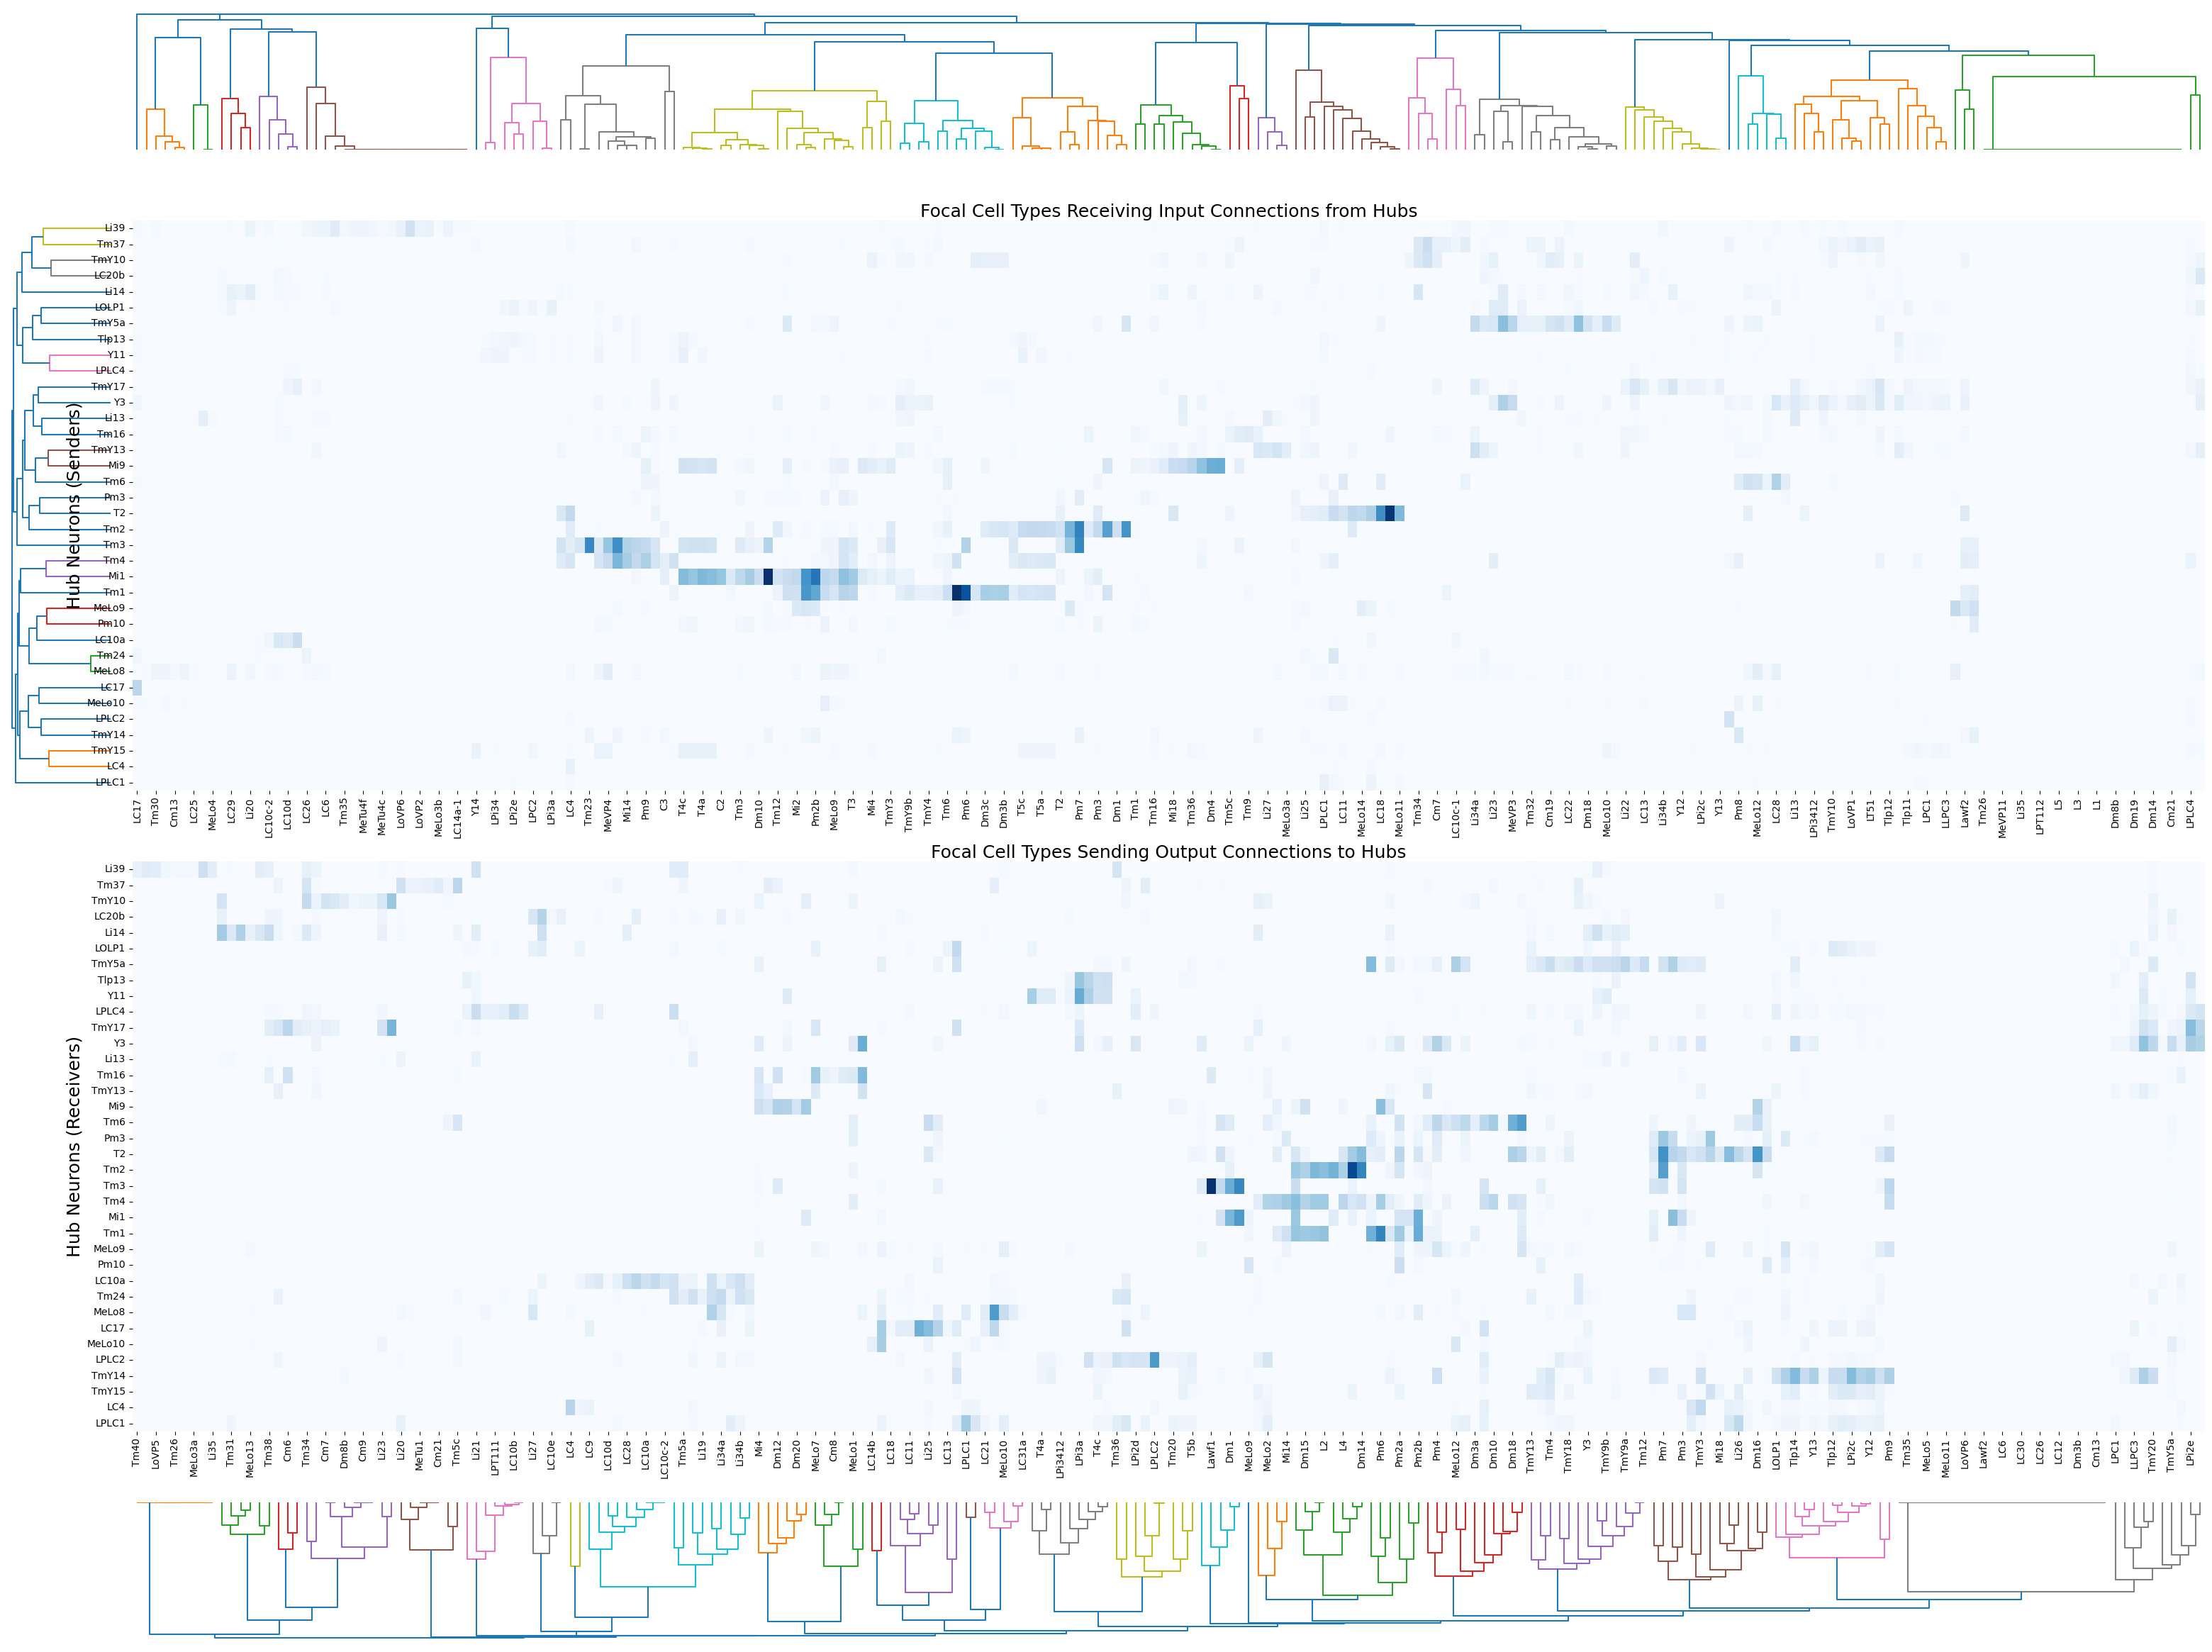

In [8]:
plot, sorted_in, sorted_out = Hub_analysis.clustering_hubs_parents_I_O(hub_in_full, hub_out_full)

In [ ]:
def clustering_hubs_parents_I_O_separate(hub_in_full, hub_out_full):

    # INPUT CLUSTERING

    # Cluster input focal cell types
    focal_in_dist = pdist(hub_in_full, metric='cosine')
    focal_in_linkage = linkage(focal_in_dist, method='average')
    focal_in_order = leaves_list(focal_in_linkage)

    # Cluster input hubs
    hub_in_dist = pdist(hub_in_full.T, metric='cosine')
    hub_in_linkage = linkage(hub_in_dist, method='average')
    hub_in_order = leaves_list(hub_in_linkage)

    # Reorder input matrix
    sorted_in = hub_in_full.iloc[
        focal_in_order,
        hub_in_order
    ]

    # OUTPUT CLUSTERING

    # Cluster output focal cell types
    focal_out_dist = pdist(hub_out_full, metric='cosine')
    focal_out_linkage = linkage(focal_out_dist, method='average')
    focal_out_order = leaves_list(focal_out_linkage)

    # Cluster output hubs
    hub_out_dist = pdist(hub_out_full.T, metric='cosine')
    hub_out_linkage = linkage(hub_out_dist, method='average')
    hub_out_order = leaves_list(hub_out_linkage)

    # Reorder output matrix
    sorted_out = hub_out_full.iloc[
        focal_out_order,
        hub_out_order
    ]


    # FIGURE
    fig = plt.figure(figsize=(40, 30))

    gs = fig.add_gridspec(
        nrows=5,
        ncols=2,

        # left = hub dendrogram
        # right = heatmap
        width_ratios=[3, 40],

        # focal dendro, heatmap, gap, focal dendro, heatmap
        height_ratios=[5, 20, 3, 5, 20],

        wspace=0.02,
        hspace=0.15
    )

    # INPUT FOCAL DENDROGRAM

    focal_in_dendro = fig.add_subplot(gs[0, 1])

    dendrogram(
        focal_in_linkage,
        ax=focal_in_dendro,
        orientation='top',
        no_labels=True,
        color_threshold=None
    )

    focal_in_dendro.axis('off')



    # INPUT HUB DENDROGRAM
    hub_in_dendro = fig.add_subplot(gs[1, 0])

    dendrogram(
        hub_in_linkage,
        ax=hub_in_dendro,
        orientation='left',
        no_labels=True,
        color_threshold=None
    )

    hub_in_dendro.axis('off')


    # INPUT HEATMAP
    ax_in = fig.add_subplot(gs[1, 1])

    sns.heatmap(
        sorted_in.T,
        cmap='Blues',
        vmin=0,
        vmax=60,
        ax=ax_in,
        cbar=False
    )

    ax_in.set_ylabel(
        "Hub Neurons (Senders)",
        fontsize=18
    )

    ax_in.set_xlabel(
        "Focal Cell Types Receiving Input Connections from Hubs",
        fontsize=18
    )

    ax_in.xaxis.set_label_position('top')

    # OUTPUT FOCAL DENDROGRAM

    focal_out_dendro = fig.add_subplot(gs[3, 1])

    dendrogram(
        focal_out_linkage,
        ax=focal_out_dendro,
        orientation='top',
        no_labels=True,
        color_threshold=None
    )

    focal_out_dendro.axis('off')

    # OUTPUT HUB DENDROGRAM
    hub_out_dendro = fig.add_subplot(gs[4, 0])

    dendrogram(
        hub_out_linkage,
        ax=hub_out_dendro,
        orientation='left',
        no_labels=True,
        color_threshold=None
    )

    hub_out_dendro.axis('off')


    # OUTPUT HEATMAP
    ax_out = fig.add_subplot(gs[4, 1])

    sns.heatmap(
        sorted_out.T,
        cmap='Blues',
        vmin=0,
        vmax=40,
        ax=ax_out,
        cbar=False
    )

    ax_out.set_ylabel(
        "Hub Neurons (Receivers)",
        fontsize=18
    )

    ax_out.set_xlabel(
        "Focal Cell Types Sending Output Connections to Hubs",
        fontsize=18
    )

    ax_out.xaxis.set_label_position('top')

    # FORMAT AXES

    for ax in [ax_in, ax_out]:

        ax.tick_params(
            axis='x',
            rotation=90,
            labelsize=10
        )

        ax.tick_params(
            axis='y',
            rotation=0,
            labelsize=10
        )


    plt.tight_layout()

    return fig, sorted_in, sorted_out

/var/folders/2f/zb94ck9x7sv6fn_sq___fw280000gn/T/ipykernel_5086/1775763180.py:181: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



ValueError: too many values to unpack (expected 3)

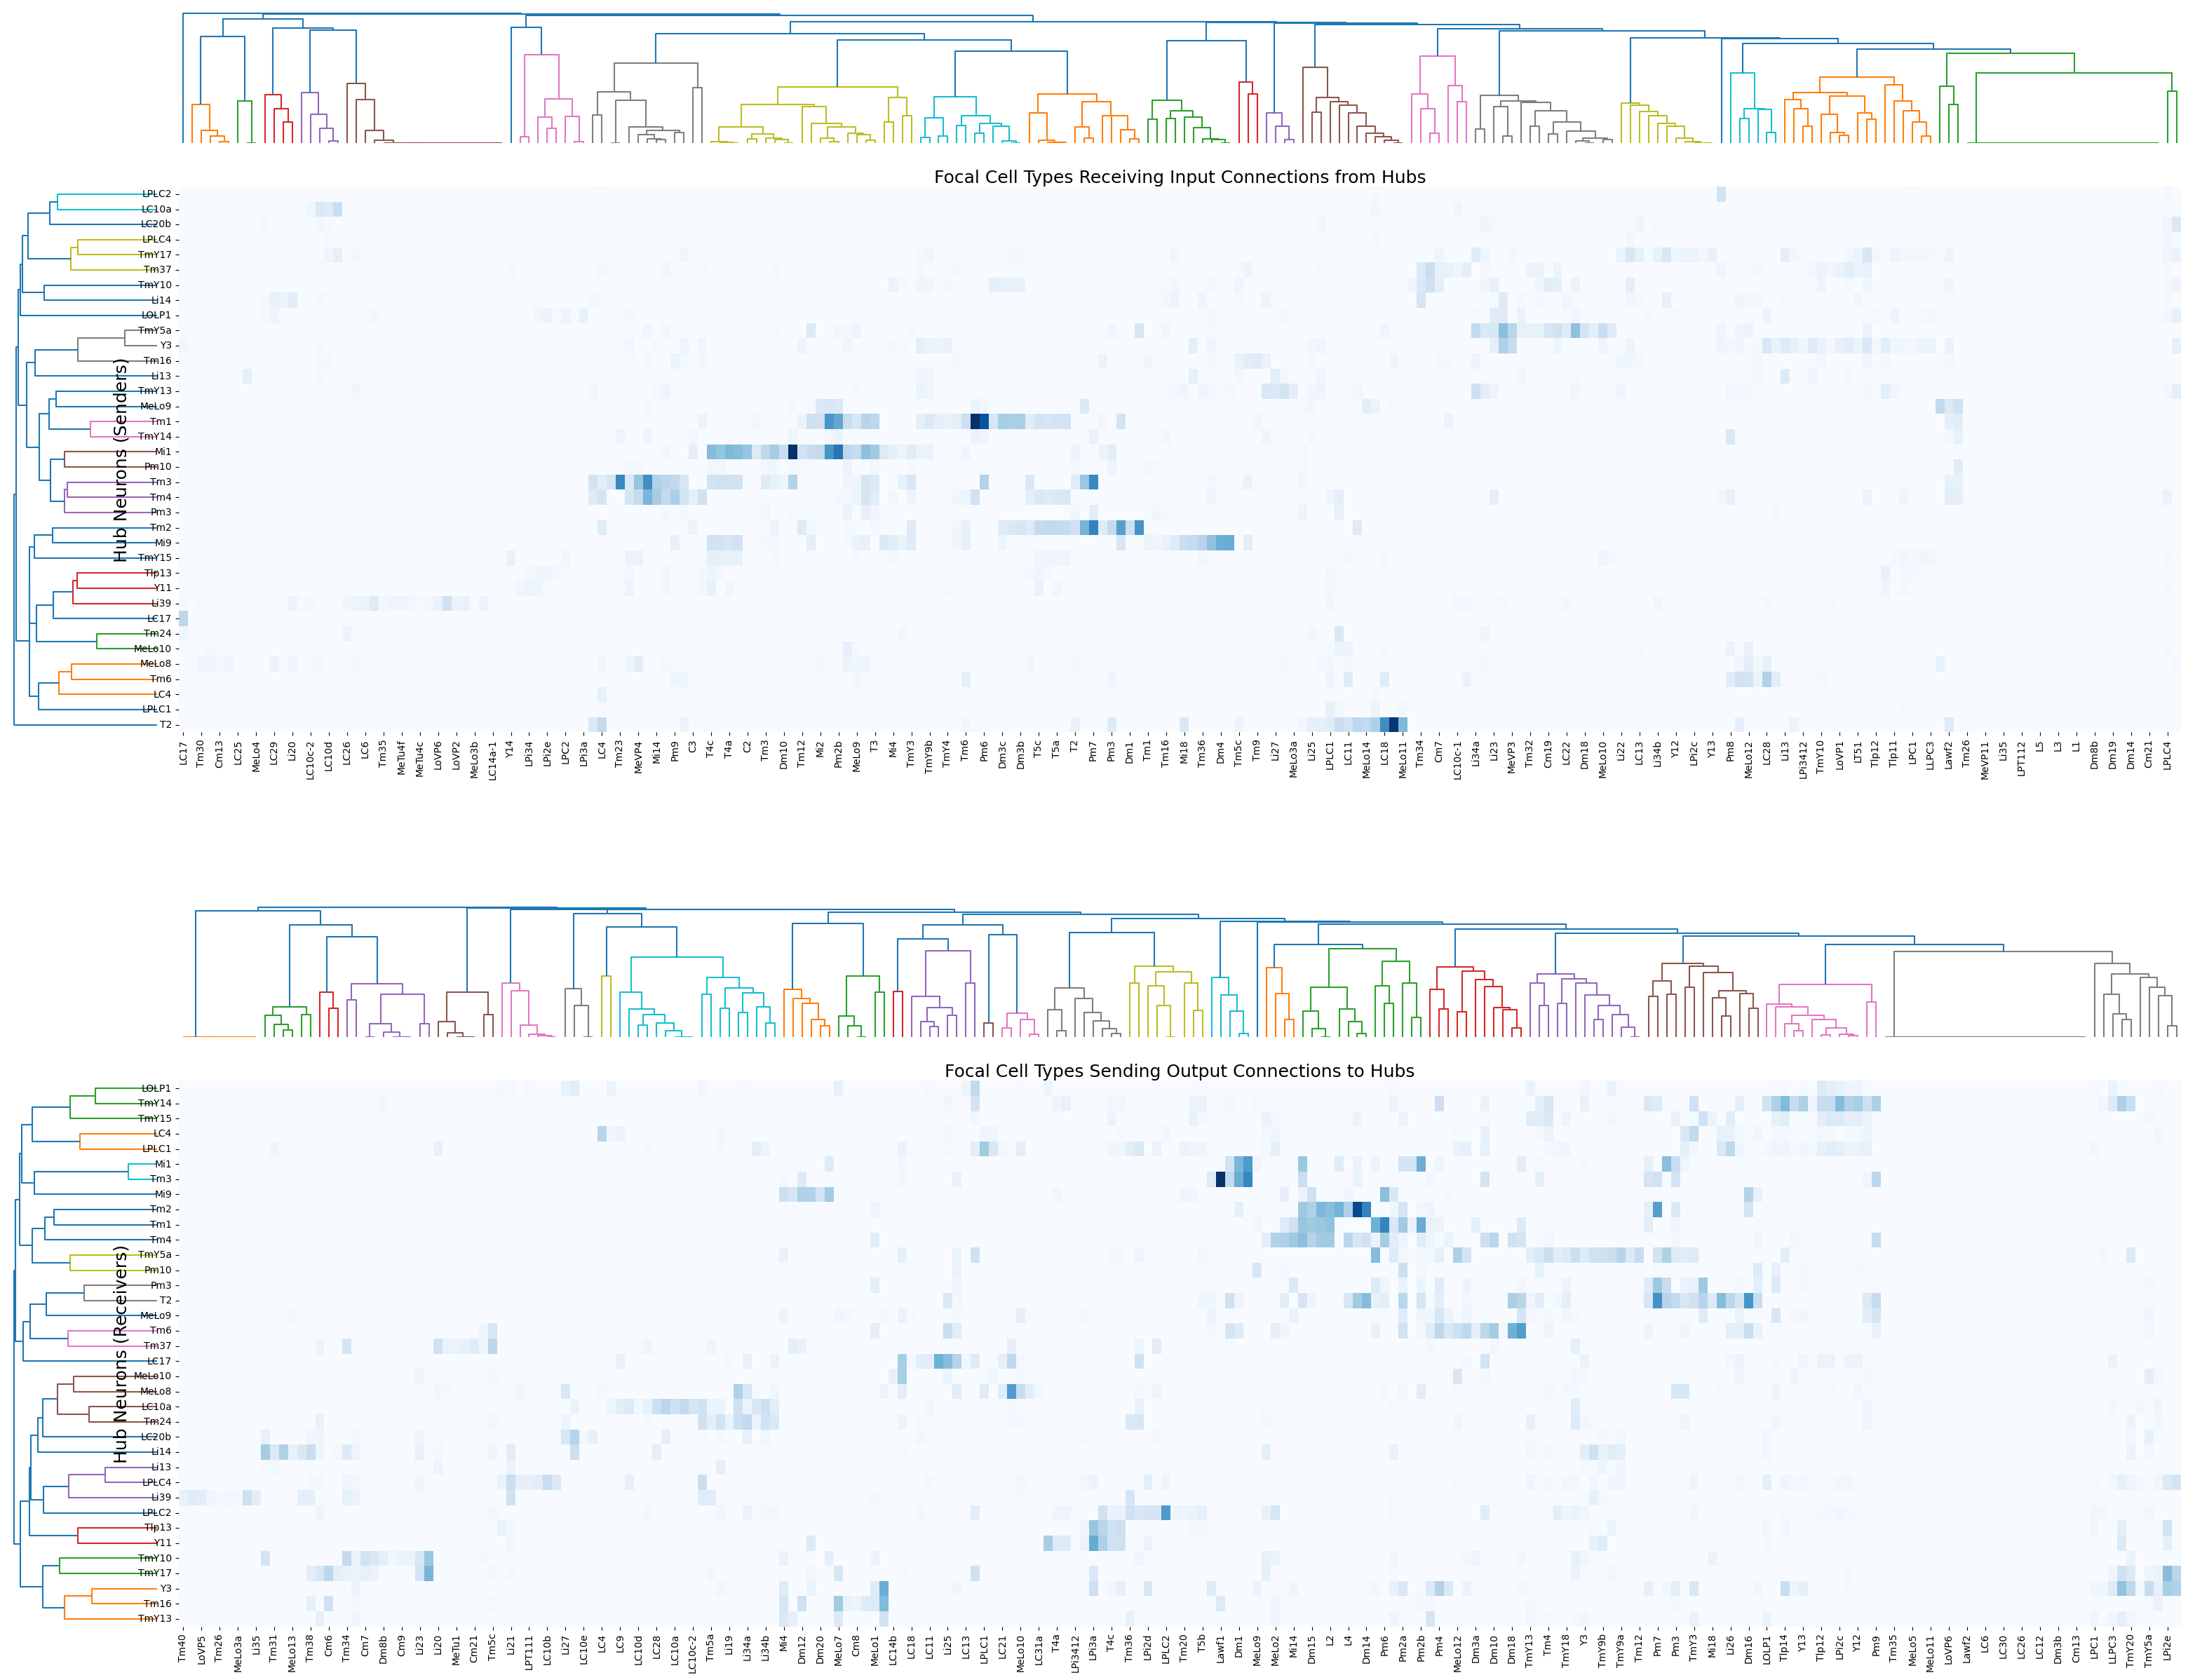

In [20]:
fig, sorted_in, sorted_out = clustering_hubs_parents_I_O_separate(hub_in_full, hub_out_full)

In [9]:
fig = px.imshow(
    sorted_in.T,
    color_continuous_scale="Blues",
    zmin=0,
    zmax=70,
    aspect="auto",
)

fig.update_layout(
    width=2000,
    height=1000,   # make tall enough for all rows
)

fig.update_yaxes(title="Hub Neurons")
fig.update_xaxes(title="Focal Cell Types get Input from hubs")

fig.show()

In [10]:
fig = px.imshow(
    sorted_out.T,
    color_continuous_scale="Blues",
    zmin=0,
    zmax=70,
    aspect="auto",
)

fig.update_layout(
    width=2000,
    height=1000,   # make tall enough for all rows
)

fig.update_yaxes(title="Hub Neurons")
fig.update_xaxes(title="Focal Cell Types Send Output to Hubs")

fig.show()

## Hub bipartites

In [11]:
bipartite_parent_input_v3_hubs , bipartite_parent_output_v3_hubs, _ = Hub_analysis.hub_bipartites_only_df(merged_partner_df,cut_bipartite_parent_input_v3, cut_bipartite_parent_output_v3)
# plot = HP_plot_v2.plot_bipartite_population('MeLo8', bipartite_parent_input_v3_hubs, bipartite_parent_output_v3_hubs)
# plot.show()

In [ ]:
# hub_neurons = merged_partner_df.loc[merged_partner_df['color_masked'].notna(), ['partner_cell']]
# pd.DataFrame(hub_neurons, columns=["hub_neuron"]).to_csv(
#     data_dir / "hub_neurons.csv",
#     index=False
# )

In [ ]:
# ALL CELL TYPES SUN PLOTS
for i in hub_neurons:
    try:
        print(f"Running: {i}")
        plot = HP_plot_v2.plot_bipartite_population(i, bipartite_parent_input_v3_hubs, bipartite_parent_output_v3_hubs)
        if plot is None:
            continue
        filename = os.path.join(bipartite_folder, f"{i}_bipartite_hub.pdf")
        plot.write_image(filename, scale=2)
    except KeyError as e:
        print(f"KeyError for {i}: missing key {e}")

# Partner Reliability

In [4]:
# # Syn position for a connection
parent = 'Pm2a'
partner = 'Mi1'
roi = ['ME(R)', 'AME(R)', 'LO(R)', 'LOP(R)']
df_celltype_1_2_fin, df_freq_bodyId_conn = reliability_filter.get_syn_position(parent, partner, roi)
plot_polka_dot = reliability_filter.plot_mean_syn(parent, partner, df_celltype_1_2_fin, df_freq_bodyId_conn)


# change this for LOP to LO to check T4a abd T5a connection. also 'pre_partner_post_parent' didnt work for pm2a mi4

  0%|          | 0/11 [00:00<?, ?it/s]

/Users/aarushivardhan/Documents/connectome/msc_av/reliability_filter.py:545: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



  0%|          | 0/89 [00:00<?, ?it/s]

/Users/aarushivardhan/Documents/connectome/msc_av/reliability_filter.py:559: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



In [7]:
plot_polka_dot

In [ ]:
# partner_rel_plot = reliability_filter.visualise_partner_reliability(bipartite_parent_input_v3, direction)

In [4]:
df_in_bipart, df_out_bipart = reliability_filter.two_way_reliability_with_celltype_size_df(bipartite_parent_input_v3, bipartite_parent_output_v3 , syn_partner_cutoff=None, syn_parent_cutoff=None, partner_reliability_cutoff=0)
df_in_bipart['parent_group'] = df_in_bipart['parent'].map(all_celltypes_list_greater_or_eq_10)
df_out_bipart['parent_group'] = df_out_bipart['parent'].map(all_celltypes_list_greater_or_eq_10)

In [7]:
reli_contact_plot = reliability_filter.two_way_reliability_with_celltype_size_plot(df_in_bipart,'reliability', 'input', "log_ratio", "parent_reliability_2", "partner_reliability") 
reli_contact_plot.show()
# fig = reliability_filter.two_way_reliability_with_celltype_size_plot(df_in_bipart, 'reliability', 'input', "log_ratio", "parent_reliability_2", "partner_reliability") #try cutting off partners below a certain number of syanpses and see what happens
# fig.show()
# contact_pattern = reliability_filter.two_way_reliability_with_celltype_size_plot(df_in_bipart, 'contact_pattern', 'input', "log_ratio", "log_avg_num_partners_contact_parent" , 'log_raw_syn_nern_partner') #try cutting off partners below a certain number of syanpses and see what happens
# contact_pattern.show()

In [9]:
reli_contact_plot.data[0].type

'scattergl'

In [8]:
reli_contact_plot.write_image("partner_reliability_fig2d.svg")

In [5]:
df_in_bipart.columns

Index(['raw_syn_partner_2', 'std_raw_syn_partner_2', 'range_raw_syn_partner_2',
       'total_partner_neurons_2', 'parent_reliability_2',
       'avg_num_parents_contact_partner_2',
       'med_num_parents_contact_partner_2', 'pcnt_output_from_partner_2',
       'raw_syn_nern_partner_2', 'std_raw_syn_nern_partner_2',
       'range_raw_syn_nern_partner_2', 'partner_rank_2', 'partner_cell',
       'raw_syn', 'std_raw_syn', 'range_raw_syn', 'num_neurons_parent_ct',
       'partner_reliability', 'avg_num_partners_contact_parent',
       'med_num_partners_contact_parent', 'pcnt_input_to_parent',
       'raw_syn_nern', 'std_raw_syn_nern', 'range_raw_syn_nern', 'parent_rank',
       'parent', 'cutoff', 'raw_syn_partner', 'raw_syn_nern_partner',
       'log_ratio', 'log_raw_syn_nern_partner', 'log_raw_syn_nern',
       'log_raw_syn', 'log_avg_num_parents_contact_partner_2',
       'log_avg_num_partners_contact_parent', 'log_ratio_contact_pattern',
       'parent_group'],
      dtype='object')

In [ ]:
# #  df to Lorenzo
# #     'raw_syn_partner', 'std_raw_syn_partner', 'range_raw_syn_partner', I removed this because although these differe depending on if you look at focal or partner perspetive (has to do with reliability). They are the same measure. Unlike Nern method. 

# bipartite_null_input = df_in_bipart[[
#        'pcnt_output_from_partner_2',
#        'raw_syn_nern_partner_2', 'std_raw_syn_nern_partner_2',
#        'range_raw_syn_nern_partner_2', 'partner_cell','total_partner_neurons_2',
#        'raw_syn', 'std_raw_syn', 'range_raw_syn', 'pcnt_input_to_parent',
#        'raw_syn_nern', 'std_raw_syn_nern', 'range_raw_syn_nern',
#        'parent', 'log_ratio',
#        'log_avg_num_partners_contact_parent', 
#        'parent_group',  'num_neurons_parent_ct', 'log_raw_syn_nern_partner', 'log_raw_syn_nern', 'log_raw_syn']]
# bipartite_null_output = df_out_bipart[[
#        'pcnt_input_to_partner_2',
#       'partner_cell','total_partner_neurons_2',
#       'raw_syn_nern_partner_2', 'std_raw_syn_nern_partner_2', 'range_raw_syn_nern_partner_2',
#        'raw_syn', 'std_raw_syn', 'range_raw_syn', 'pcnt_output_from_parent',
#        'raw_syn_nern', 'std_raw_syn_nern', 'range_raw_syn_nern',
#        'parent', 'log_ratio',
#        'log_avg_num_partners_contact_parent', 
#        'parent_group',  'num_neurons_parent_ct', 'log_raw_syn_nern_partner', 'log_raw_syn_nern', 'log_raw_syn']]

In [ ]:
# bipartite_null_output.to_csv(data_dir/'send_lorenzo'/'bipartite_null_output.csv', index=False)
# bipartite_null_input.to_csv(data_dir/'send_lorenzo'/'bipartite_null_input.csv', index=False)


# Thesis Figures

## This to show how many connection I am dealing with in my bipartites after (10 cts parents, parent reliability with strength, partner reliability)

In [ ]:
#  caveat with my method in post processing, the df I am dealing with is parent/focal ID --> (partners summed, so the neuron to neuron connectivity is not here. Each row is a unique parent Id and partner type). Should be ok as this is the starting matrix i am comparing everything to. 
partner_folder = "partner_data_28_04_2026"

input_dfs = []
output_dfs = []

for parent_name in all_celltypes_R_list:

    # INPUT
    filename = f"input_{parent_name}_df.pkl"
    filepath = data_dir / partner_folder / filename

    with open(filepath, "rb") as f:
        celltype_df = pickle.load(f)

    _, _, _, df_input = pre_HP.get_input_connections_processing(celltype_df)

    input_dfs.append(df_input)

    # OUTPUT
    filename = f"output_{parent_name}_df.pkl"
    filepath = data_dir / partner_folder / filename

    with open(filepath, "rb") as f:
        celltype_df = pickle.load(f)

    _, _, _, df_output = pre_HP.get_output_connections_processing(celltype_df)

    output_dfs.append(df_output)

# Concatenate all processed dataframes
all_input_df = pd.concat(input_dfs, ignore_index=True)
all_output_df = pd.concat(output_dfs, ignore_index=True)

In [ ]:
# see how man  connection are there when we narrow to cell types eq or above 10 
partner_folder = "partner_data_28_04_2026"

input_dfs_10 = []
output_dfs_10 = []

for parent_name in all_celltypes_list_greater_or_eq_10:

    # INPUT
    filename = f"input_{parent_name}_df.pkl"
    filepath = data_dir / partner_folder / filename

    with open(filepath, "rb") as f:
        celltype_df = pickle.load(f)

    _, _, _, df_input = pre_HP.get_input_connections_processing(celltype_df)

    input_dfs_10.append(df_input)

    # OUTPUT
    filename = f"output_{parent_name}_df.pkl"
    filepath = data_dir / partner_folder / filename

    with open(filepath, "rb") as f:
        celltype_df = pickle.load(f)

    _, _, _, df_output = pre_HP.get_output_connections_processing(celltype_df)

    output_dfs_10.append(df_output)

# Concatenate all processed dataframes
all_input_df_10 = pd.concat(input_dfs_10, ignore_index=True)
all_output_df_10 = pd.concat(output_dfs_10, ignore_index=True)

In [ ]:
input_monopartite_table_thesis, output_monopartite_table_thesis = Handshake_pair_v2.monopartite_population_first(all_celltypes_list_greater_or_eq_10, x_cutoff=3, y_cutoff=0.8)

In [ ]:
input_monopartite_table_thesis[input_monopartite_table_thesis['cutoff'] == 1]

,partner_cell,raw_syn,num_neurons_parent_ct,partner_reliability,avg_num_partners_contact_parent,med_num_partners_contact_parent,pcnt_input_to_parent,raw_syn_nern,parent_rank,parent,cutoff
0,Mi15,2.0,17,1.000000,42.117647,38.0,19.980119,135.0,1,aMe5,1
1,aMe5,3.0,17,1.000000,13.529412,14.0,8.243243,53.0,2,aMe5,1
2,MeTu3c,2.0,17,0.941176,11.529412,11.0,4.653527,26.5,3,aMe5,1
3,Mi10,1.0,17,1.000000,12.470588,10.0,3.108108,23.0,4,aMe5,1
4,Cm31b,12.0,17,1.000000,1.000000,1.0,2.409639,12.0,5,aMe5,1
...,...,...,...,...,...,...,...,...,...,...,...
68220,Dm6,5.0,892,0.998879,3.008969,3.0,7.399103,16.0,3,T1,1
68221,Dm19,3.0,892,0.998879,3.878924,4.0,5.257257,11.0,4,T1,1
68222,C2,4.0,892,0.949552,0.985426,1.0,1.953810,4.0,5,T1,1
68223,Dm17,2.0,892,0.855381,1.239910,1.0,1.150737,3.0,6,T1,1


In [ ]:
rows = []

def add_row(condition, original, parent10, filtered, partner):
    rows.append({
        "type": condition,
        "connection_type": "original_conn",
        "value": original
    })
    rows.append({
        "type": condition,
        "connection_type": "parent_conn_10cts",
        "value": parent10
    })
    rows.append({
        "type": condition,
        "connection_type": "parent_conn_filtered",
        "value": filtered
    })
    rows.append({
        "type": condition,
        "connection_type": "partner_conn_filtered",
        "value": partner
    })

# input
add_row(
    "input",
    len(all_input_df),
    len(all_input_df_10),
    len(input_monopartite_table_thesis[input_monopartite_table_thesis['cutoff'] == 1]),
    len(cut_bipartite_parent_input_v3)
)

# output
add_row(
    "output",
    len(all_output_df),
    len(all_output_df_10),
    len(output_monopartite_table_thesis[output_monopartite_table_thesis['cutoff'] == 1]),
    len(cut_bipartite_parent_output_v3)
)

# # both
# add_row(
#     "both",
#     len(all_input_df) + len(all_output_df),
#     len(all_input_df_10) + len(all_output_df_10),
#     len(input_monopartite_table_thesis[input_monopartite_table_thesis['cutoff'] == 1])
#     + len(output_monopartite_table_thesis[output_monopartite_table_thesis['cutoff'] == 1]),
#     len(cut_bipartite_parent_input_v3) + len(cut_bipartite_parent_output_v3)
# )

df_long = pd.DataFrame(rows)


In [ ]:
df_long

,type,connection_type,value
0,input,original_conn,2290465
1,input,parent_conn_10cts,2162235
2,input,parent_conn_filtered,7661
3,input,partner_conn_filtered,5067
4,output,original_conn,2694730
5,output,parent_conn_10cts,2538090
6,output,parent_conn_filtered,7741
7,output,partner_conn_filtered,5645


In [ ]:
rename_map = {
    "original_conn": "Full Connectome",
    "parent_conn_10cts": "≥10 neurons per cell type",
    "parent_conn_filtered": "Focal reliability ≥ 0.8 & strength ≥ 3%",
    "partner_conn_filtered": "Partner reliability ≥ 0.8"
}

df_plot = df_long.copy()
df_plot["connection_type"] = df_plot["connection_type"].replace(rename_map)

order = [
    "Full Connectome",
    "≥10 neurons per cell type",
    "Focal reliability ≥ 0.8 & strength ≥ 3%",
    "Partner reliability ≥ 0.8"
]

df_plot["connection_type"] = pd.Categorical(
    df_plot["connection_type"],
    categories=order,
    ordered=True
)
color_map = {
    "input": "green",
    "output": "blue"
}
fig = go.Figure()

fig.add_trace(go.Bar(
    x=df_plot[df_plot["type"] == "input"]["connection_type"],
    y=df_plot[df_plot["type"] == "input"]["value"],
    name="input",
    marker_color="green"
))

fig.add_trace(go.Bar(
    x=df_plot[df_plot["type"] == "output"]["connection_type"],
    y=df_plot[df_plot["type"] == "output"]["value"],
    name="output",
    marker_color="blue"
))

fig.update_layout(
    barmode="group",
    xaxis_title="Thresholding Stage →",
    yaxis_title="# Connections (log scale)",
    plot_bgcolor='white',
    paper_bgcolor='white'
)

fig.update_yaxes(type="log" , title_font=dict(size=25), tickfont=dict(size=18))
fig.update_xaxes(title_font=dict(size=25), tickfont=dict(size=18))

fig.show()


##  see dist of conn in focal-partner (95) and dvided 10 pcnt and higher compared to 10 pcnt lower

In [66]:
## #####################  # #####################
def plot_partner_threshold_comparison(direction, x_axis, threshold=10):
    cfg = pre_HP.configpath()
    data_dir = Path(cfg['data_dir'])

    if direction not in ['input', 'output']:
        raise ValueError("Direction must be 'input' or 'output'")

    filepath = (
        data_dir / "df_all_parents_partners_95_input.pkl"
        if direction == "input"
        else data_dir / "df_all_parents_partners_95_output.pkl"
    )

    with open(filepath, "rb") as f:
        df = pickle.load(f)

    # --- BINNING STEP ---
    df["bin"] = np.where(df[x_axis] < threshold, f"<{threshold}%", f"≥{threshold}%")

    # count per bin
    summary = df["bin"].value_counts().reset_index()
    summary.columns = ["bin", "count"]
    summary["percent"] = 100 * summary["count"] / summary["count"].sum().round(1)

    # --- PLOT ---
    fig = px.bar(
        summary,
        x="bin",
        y="percent",
        text="percent",
        color="bin",
        color_discrete_map={
            f"≤{threshold}%": "green",
            f">{threshold}%": "red"
        }
    )

    fig.update_layout(
        title=f"Partner Distribution Split at {threshold}% ({direction})",
        xaxis_title="Connection Strength binned (above 10 and below 10 pcnt)",
        yaxis_title="Number of Connections",
        plot_bgcolor="white",
        paper_bgcolor="white"
    )

    fig.update_traces(textposition="outside", texttemplate="%{text:.1f}")

    fig.show()

    return summary
comparison_df = plot_partner_threshold_comparison(direction, 'median_pcnt_ct_total_ct', threshold=10)

In [59]:
df_all_parents_partners_95 = Hub_analysis.plot_all_partner_distribution_95('input', "median_pcnt_ct_total_ct" , 200,  "Y")

## Partner specificty and bipartites (high specifcity = stronger investment)

In [85]:
# ##################### Partner specificty and bipartites # #####################
plot , hierarchicial_ir_ct = pre_HP.plot_box_top_ct_coverage_allgroups(df5, pivot_df, direction)

In [ ]:
plot.show()

In [86]:
n = max(1, int(len(hierarchicial_ir_ct) * 0.20))

top_10_ir = hierarchicial_ir_ct[:n]
bottom_10_ir = hierarchicial_ir_ct[-n:]

In [87]:
specificty_top3_ratios = []
for top in top_10_ir:
    df = cut_bipartite_parent_input_v3[cut_bipartite_parent_input_v3['parent'] == top]
    median_val = df['pcnt_input_to_parent'].median()
    top3_mean = df['pcnt_input_to_parent'].head(3).mean()
    num_partners = df['partner_cell'].size

    strength_ratio = top3_mean / median_val
    specificty_top3_ratios.append({'parent' : top, "group": "high_specificity", 'strength_ratio': strength_ratio, 'num_partners': num_partners})

for bottom in bottom_10_ir:
    df = cut_bipartite_parent_input_v3[cut_bipartite_parent_input_v3['parent'] == bottom]
    median_val = df['pcnt_input_to_parent'].median()
    bottom3_mean = df['pcnt_input_to_parent'].head(3).mean()
    num_partners = df['partner_cell'].size

    strength_ratio = bottom3_mean / median_val
    specificty_top3_ratios.append({'parent' : bottom, "group": "low_specificity", 'strength_ratio': strength_ratio, 'num_partners': num_partners})
    
specificty_top3_ratios_df = pd.DataFrame(specificty_top3_ratios)

In [91]:
fig = px.box(
    specificty_top3_ratios_df,
    x="group",
    y="strength_ratio",
    title="Top 20% High vs Low Specificity Focals",
    labels={
        "strength_ratio": "Top-3 Input to Focal Strength Ratio",
        "group": "Specificity group"
    }
)

fig.update_layout(
    plot_bgcolor="white",
    paper_bgcolor="white",
    xaxis_tickangle=0,
    height=600,
    font=dict(size=14)
)

fig.update_xaxes(showgrid=False, tickfont=dict(size=18))
fig.update_yaxes(
    tickfont=dict(size=18)
)

fig.show()

## Partner self-connectivity with partner convergence and see if the HP are also strong

In [33]:
df_in_bipart, df_out_bipart = reliability_filter.two_way_reliability_with_celltype_size_df(bipartite_parent_input_v3, bipartite_parent_output_v3 , syn_partner_cutoff=None, syn_parent_cutoff=None, partner_reliability_cutoff=0.8)
df_in_bipart['parent_group'] = df_in_bipart['parent'].map(all_celltypes_list_greater_or_eq_10)
df_out_bipart['parent_group'] = df_out_bipart['parent'].map(all_celltypes_list_greater_or_eq_10)
contact_pattern = reliability_filter.two_way_reliability_with_celltype_size_plot(df_in_bipart, 'contact_pattern', 'input', "log_avg_num_partners_contact_parent" , 'parent_group') #try cutting off partners below a certain number of syanpses and see what happens

In [34]:
df_in_temp = df_in_bipart[['parent_group', 'log_ratio', 'log_avg_num_partners_contact_parent', 'pcnt_input_to_parent', 'pcnt_output_from_partner_2' , 'parent', 'partner_cell']].copy()
df_in_temp['direction'] = 'input'
df_out_temp = df_out_bipart[['parent_group', 'log_ratio', 'log_avg_num_partners_contact_parent', 'pcnt_output_from_parent', 'pcnt_input_to_partner_2', 'parent', 'partner_cell']].copy()
df_out_temp['direction'] = 'output'

In [ ]:
# df_in_filt = df_in_temp[
#     (df_in_temp['log_ratio'] == 0) &
#     (df_in_temp['parent_group'] == 'VPN') &
#     (df_in_temp['log_avg_num_partners_contact_parent'] >= 1.2)
# ]

# df_out_filt = df_out_temp[
#     (df_out_temp['log_ratio'] == 0) &
#     (df_out_temp['parent_group'] == 'VPN') #&
#     (df_out_temp['log_avg_num_partners_contact_parent'] >= 1.2) ]

df_in_filt = df_in_temp[
    (df_in_temp['log_ratio'] == 0) &
    (df_in_temp['parent_group'] == 'VPN')
]

df_out_filt = df_out_temp[
    (df_out_temp['log_ratio'] == 0) &
    (df_out_temp['parent_group'] == 'VPN')]

partner_convergence_VPN = df_in_filt.merge( #  all VPNS on the weird peak
    df_out_filt,
    left_on=['parent', 'partner_cell'],
    right_on=['partner_cell', 'parent'],
    how="inner"
)
#  Out of all the VPNs on the weird peak how many show Handshake Pairs 
partner_convergence_VPN_filt = partner_convergence_VPN[
    (partner_convergence_VPN['pcnt_input_to_parent'] >= 10) &
    (partner_convergence_VPN['pcnt_output_from_partner_2'] >= 10) &
    (partner_convergence_VPN['pcnt_output_from_parent'] >= 10) &
    (partner_convergence_VPN['pcnt_input_to_partner_2'] >= 10) &
    np.isclose(partner_convergence_VPN['pcnt_output_from_parent'], partner_convergence_VPN['pcnt_input_to_partner_2'], rtol=0.4) &
    np.isclose(partner_convergence_VPN['pcnt_output_from_partner_2'], partner_convergence_VPN['pcnt_input_to_parent'], rtol=0.4) 
]

In [42]:
# df_in_filt_oncn = df_in_temp[
#     (df_in_temp['log_ratio'] == 0) &
#     (df_in_temp['parent_group'] == 'ONCN') #&
#     (df_in_temp['log_avg_num_partners_contact_parent'] <= 0.27)]

# df_out_filt_oncn = df_out_temp[
#     (df_out_temp['log_ratio'] == 0) &
#     (df_out_temp['parent_group'] == 'ONCN') #&
#     (df_out_temp['log_avg_num_partners_contact_parent'] <= 0.27) ]

df_in_filt_oncn = df_in_temp[
    (df_in_temp['log_ratio'] == 0) &
    (df_in_temp['parent_group'] == 'ONCN')]

df_out_filt_oncn = df_out_temp[
    (df_out_temp['log_ratio'] == 0) &
    (df_out_temp['parent_group'] == 'ONCN') ]

partner_convergence_ONCN = df_in_filt_oncn.merge( #  all ONCNS on the weird peak below
    df_out_filt_oncn,
    left_on=['parent', 'partner_cell'],
    right_on=['partner_cell', 'parent'],
    how="inner"
)
#  Out of all the ONCNs on the weird bottom peak how many show Handshake Pairs 
partner_convergence_ONCN_filt = partner_convergence_ONCN[
    (partner_convergence_ONCN['pcnt_input_to_parent'] >= 10) &
    (partner_convergence_ONCN['pcnt_output_from_partner_2'] >= 10) &
    (partner_convergence_ONCN['pcnt_output_from_parent'] >= 10) &
    (partner_convergence_ONCN['pcnt_input_to_partner_2'] >= 10) &
    np.isclose(partner_convergence_ONCN['pcnt_output_from_parent'], partner_convergence_ONCN['pcnt_input_to_partner_2'], rtol=0.4) &
    np.isclose(partner_convergence_ONCN['pcnt_output_from_partner_2'], partner_convergence_ONCN['pcnt_input_to_parent'], rtol=0.4) 
]

In [44]:
# df_in_filt_onin = df_in_temp[
#     (df_in_temp['log_ratio'] == 0) &
#     (df_in_temp['parent_group'] == 'ONIN') &
#     (df_in_temp['log_avg_num_partners_contact_parent'] <= 0.27)]

# df_out_filt_onin = df_out_temp[
#     (df_out_temp['log_ratio'] == 0) &
#     (df_out_temp['parent_group'] == 'ONIN') &
#     (df_out_temp['log_avg_num_partners_contact_parent'] <= 0.27) ]

df_in_filt_onin = df_in_temp[
    (df_in_temp['log_ratio'] == 0) &
    (df_in_temp['parent_group'] == 'ONIN')]

df_out_filt_onin = df_out_temp[
    (df_out_temp['log_ratio'] == 0) &
    (df_out_temp['parent_group'] == 'ONIN')]

partner_convergence_ONIN = df_in_filt_onin.merge( #  all onin on the weird peak below
    df_out_filt_onin,
    left_on=['parent', 'partner_cell'],
    right_on=['partner_cell', 'parent'],
    how="inner"
)
#  Out of all the ONINs on the weird bottom peak how many show Handshake Pairs 
partner_convergence_ONIN_filt = partner_convergence_ONIN[
    (partner_convergence_ONIN['pcnt_input_to_parent'] >= 10) &
    (partner_convergence_ONIN['pcnt_output_from_partner_2'] >= 10) &
    (partner_convergence_ONIN['pcnt_output_from_parent'] >= 10) &
    (partner_convergence_ONIN['pcnt_input_to_partner_2'] >= 10) &
    np.isclose(partner_convergence_ONIN['pcnt_output_from_parent'], partner_convergence_ONIN['pcnt_input_to_partner_2'], rtol=0.4) &
    np.isclose(partner_convergence_ONIN['pcnt_output_from_partner_2'], partner_convergence_ONIN['pcnt_input_to_parent'], rtol=0.4) 
]

In [45]:
df_partner_convergence = []

def add_group(nern_group, self_conn, self_hp, non_self, non_self_hp):
    df_partner_convergence.extend([
        {"conn_type": nern_group, "type": "Self-Connectivity", "num": self_conn , "type_2": "1"},
        {"conn_type": nern_group, "type": "Self-Connectivity Bidirectional HP", "num": self_hp, "type_2": "1"},
        {"conn_type": nern_group, "type": "Non Self-Connectivity", "num": non_self, "type_2": "0"},
        {"conn_type": nern_group, "type": "Non Self-Connectivity HP", "num": non_self_hp, "type_2": "0"}
    ])

# ONIN
add_group("ONIN", partner_convergence_ONIN['parent_group_x'].size-partner_convergence_ONIN_filt['parent_group_x'].size, partner_convergence_ONIN_filt['parent_group_x'].size, 0, 0)

# ONCN
add_group("ONCN", 1, 0 , 3 , 1)

# VPN
add_group("VPN", partner_convergence_VPN['parent_group_x'].size-partner_convergence_VPN_filt['parent_group_x'].size, partner_convergence_VPN_filt['parent_group_x'].size, 0, 0)


df_partner_convergence = pd.DataFrame(df_partner_convergence)


In [46]:
partner_converegence_strength = pd.concat([partner_convergence_ONIN, partner_convergence_ONCN, partner_convergence_VPN], ignore_index=True)

In [40]:
df_partner_convergence

,conn_type,type,num,type_2
0,ONIN,Self-Connectivity,6,1
1,ONIN,Self-Connectivity Bidirectional HP,0,1
2,ONIN,Non Self-Connectivity,0,0
3,ONIN,Non Self-Connectivity HP,0,0
4,ONCN,Self-Connectivity,1,1
5,ONCN,Self-Connectivity Bidirectional HP,0,1
6,ONCN,Non Self-Connectivity,3,0
7,ONCN,Non Self-Connectivity HP,1,0
8,VPN,Self-Connectivity,16,1
9,VPN,Self-Connectivity Bidirectional HP,5,1


In [47]:
# this plot is not helpful 
plot = px.bar(df_partner_convergence, x="conn_type", y="num", color="type")
plot.update_layout(
    plot_bgcolor="white",
    paper_bgcolor="white",
    height=600
)

plot.show()

In [48]:
plot_strength = px.scatter(
    partner_converegence_strength,
    x="pcnt_input_to_parent",
    y="pcnt_output_from_partner_2",
    color="parent_group_x",
    hover_data=['parent_x', 'partner_cell_x']
)

plot_strength.update_layout(
    plot_bgcolor="white",
    paper_bgcolor="white",
    height=600,
    width=600  # optional, makes the figure square
)

plot_strength.update_xaxes(tickfont=dict(size=18))
plot_strength.update_yaxes(
    tickfont=dict(size=18),
    scaleanchor="x",
    scaleratio=1
)

plot_strength.add_shape(
    type="line",
    x0=0, y0=0, x1=1, y1=1,
    xref="paper", yref="paper",
    line=dict(dash="dash", color="gray")
)

## Hubs quantification

In [ ]:
# how man hubs connect i-o hubs and o only hubs 

In [42]:
bipartite_parent_input_v3_hubs , bipartite_parent_output_v3_hubs = Hub_analysis.hub_bipartites_only_df(merged_partner_df,cut_bipartite_parent_input_v3, cut_bipartite_parent_output_v3)

In [44]:
O_hubs = (merged_partner_df[(merged_partner_df['freq_output_all_ranks'] > 30) & (merged_partner_df['freq_input_all_ranks'] < 30)])['partner_cell'].to_list()
I_O_hubs = (merged_partner_df[(merged_partner_df['freq_input_all_ranks'] > 30)])['partner_cell'].to_list()
bipartite_parent_input_v3_hubs['num_partners_hub'] = bipartite_parent_input_v3_hubs.groupby('parent')['partner_cell'].transform('size')
bipartite_parent_output_v3_hubs['num_partners_hub'] = bipartite_parent_output_v3_hubs.groupby('parent')['partner_cell'].transform('size')
df_input = (
    bipartite_parent_input_v3_hubs[
        ['parent', 'partner_cell', 'num_partners_hub']
    ]
)

df_input['direction'] = 'input'

df_output = (
    bipartite_parent_output_v3_hubs[
        ['parent', 'partner_cell', 'num_partners_hub']
    ]
)

df_output['direction'] = 'output'

/var/folders/2f/zb94ck9x7sv6fn_sq___fw280000gn/T/ipykernel_2319/1153569302.py:3: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/var/folders/2f/zb94ck9x7sv6fn_sq___fw280000gn/T/ipykernel_2319/1153569302.py:4: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/var/folders/2f/zb94ck9x7sv6fn_sq___fw280000gn/T/ipykernel_2319/1153569302.py:11: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the doc

In [45]:
df_compare = df_input.merge(
    df_output,
    on='parent',
    how='outer',
    suffixes=('_input', '_output')
)
df_compare['num_partners_hub_total'] = (df_compare['num_partners_hub_input'] + df_compare['num_partners_hub_output'])


In [46]:
df_compare.loc[df_compare['parent'].isin(O_hubs), 'hub_type'] = 'O'
df_compare.loc[df_compare['parent'].isin(I_O_hubs), 'hub_type'] = 'I_O'

In [47]:
df_compare

,parent,partner_cell_input,num_partners_hub_input,direction_input,partner_cell_output,num_partners_hub_output,direction_output,num_partners_hub_total,hub_type
0,LC10a,LC10a,11,input,LC10a,2,output,13,O
1,LC10a,LC10a,11,input,MeLo8,2,output,13,O
2,LC10a,LC20b,11,input,LC10a,2,output,13,O
3,LC10a,LC20b,11,input,MeLo8,2,output,13,O
4,LC10a,MeLo8,11,input,LC10a,2,output,13,O
...,...,...,...,...,...,...,...,...,...
3221,Y3,Li13,18,input,Mi1,16,output,34,I_O
3222,Y3,Li13,18,input,LC10a,16,output,34,I_O
3223,Y3,Li13,18,input,TmY17,16,output,34,I_O
3224,Y3,Li13,18,input,Li39,16,output,34,I_O


In [48]:
fig = px.box(
    df_compare,
    x="hub_type",
    y="num_partners_hub_total",
    title="How Many Hub-Hub Contacts: I-O vs O Hubs",
    labels={
        "hub_type": "Hub type",
        "num_partners_hub_total": "Number of hub partners",
        "direction": "Direction"
    }
)

fig.update_layout(
    plot_bgcolor="white",
    paper_bgcolor="white",
    height=600
)

fig.show()